In [1]:
# Step 1 : import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [9]:
# Step 2 : load the dataset
with np.load("imdb.npz",allow_pickle=True) as data:
    x_train,y_train = data["x_train"],data["y_train"]
    x_test,y_test = data["x_test"],data["y_test"]

In [10]:
# Step 3 : Preprocessing
x_train = pad_sequences(x_train,maxlen=200)
x_test = pad_sequences(x_test,maxlen=200)

In [11]:
# Step 4 : Calcualate vocab size 
vocab_size = max(np.max(x_train),np.max(x_test)) + 1
print(vocab_size)

88584


In [12]:
# Step 5 : Build the Model 
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size,32),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1,activation='sigmoid')
])

In [13]:
# Step 6 : Compile the model 
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [14]:
# Step 7 : Train the model 
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_data=(x_test,y_test)
)

Epoch 1/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 61s 146ms/step - accuracy: 0.8002 - loss: 0.4219 - val_accuracy: 0.8330 - val_loss: 0.3856
Epoch 2/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 53s 136ms/step - accuracy: 0.9255 - loss: 0.2048 - val_accuracy: 0.8639 - val_loss: 0.3583
Epoch 3/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 57s 145ms/step - accuracy: 0.9627 - loss: 0.1078 - val_accuracy: 0.8601 - val_loss: 0.3606


In [15]:
# Step 8 : Evaluate The model 
loss,accuracy = model.evaluate(x_test,y_test)
print(accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.8601 - loss: 0.3606
0.8601199984550476


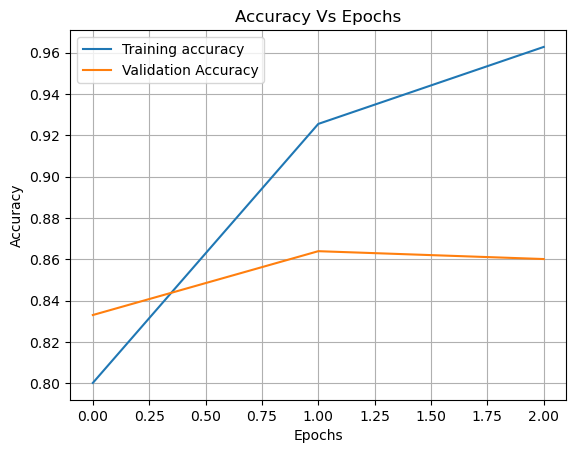

In [16]:
# Step 9 : plotting 
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.title("Accuracy Vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [17]:
# Step 10 : Testing 
predictions = model.predict(x_test[:5])

for i in range(5):
    if predictions[i][0]>=0.5:
        print("Positive")
    else:
        print("Negative")
    print("Actual : ","Positive" if y_test[i]==1 else "Negative")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step
Positive
Actual :  Positive
Positive
Actual :  Positive
Positive
Actual :  Positive
Positive
Actual :  Positive
Positive
Actual :  Positive
